In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import datetime as dt
import numpy as np 

main_df=pd.read_csv('../data/train.csv',index_col='id')
oil_df=pd.read_csv('../data/oil.csv')
hol_event_df=pd.read_csv('../data/holidays_events.csv')
stores_df=pd.read_csv('../data/stores.csv')
#transactions is probably source of data leakage

In [2]:
print(f"shape: {main_df.shape}")
main_df.head()               

shape: (3000888, 5)


,date,store_nbr,family,sales,onpromotion
id,,,,,
0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,2013-01-01,1,BABY CARE,0.0,0
2,2013-01-01,1,BEAUTY,0.0,0
3,2013-01-01,1,BEVERAGES,0.0,0
4,2013-01-01,1,BOOKS,0.0,0


In [3]:
main_df.dtypes

date            object
store_nbr        int64
family          object
sales          float64
onpromotion      int64
dtype: object

In [4]:
main_df.isna().sum().sum()

np.int64(0)

In [5]:
for i,col in enumerate(main_df.columns):
    print(f"{i+1}-> Feature:{col}             ({main_df[col].nunique()} unique values)               {main_df[col].unique()}")

1-> Feature:date             (1684 unique values)               ['2013-01-01' '2013-01-02' '2013-01-03' ... '2017-08-13' '2017-08-14'
 '2017-08-15']
2-> Feature:store_nbr             (54 unique values)               [ 1 10 11 12 13 14 15 16 17 18 19  2 20 21 22 23 24 25 26 27 28 29  3 30
 31 32 33 34 35 36 37 38 39  4 40 41 42 43 44 45 46 47 48 49  5 50 51 52
 53 54  6  7  8  9]
3-> Feature:family             (33 unique values)               ['AUTOMOTIVE' 'BABY CARE' 'BEAUTY' 'BEVERAGES' 'BOOKS' 'BREAD/BAKERY'
 'CELEBRATION' 'CLEANING' 'DAIRY' 'DELI' 'EGGS' 'FROZEN FOODS' 'GROCERY I'
 'GROCERY II' 'HARDWARE' 'HOME AND KITCHEN I' 'HOME AND KITCHEN II'
 'HOME APPLIANCES' 'HOME CARE' 'LADIESWEAR' 'LAWN AND GARDEN' 'LINGERIE'
 'LIQUOR,WINE,BEER' 'MAGAZINES' 'MEATS' 'PERSONAL CARE' 'PET SUPPLIES'
 'PLAYERS AND ELECTRONICS' 'POULTRY' 'PREPARED FOODS' 'PRODUCE'
 'SCHOOL AND OFFICE SUPPLIES' 'SEAFOOD']
4-> Feature:sales             (379610 unique values)               [0.000000e+00 2.000000e+0

In [6]:
print(f"shape:{oil_df.shape}")
oil_df.head(5)

shape:(1218, 2)


,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20


In [7]:
oil_df.isnull().sum()

date           0
dcoilwtico    43
dtype: int64

<Axes: xlabel='date', ylabel='dcoilwtico'>

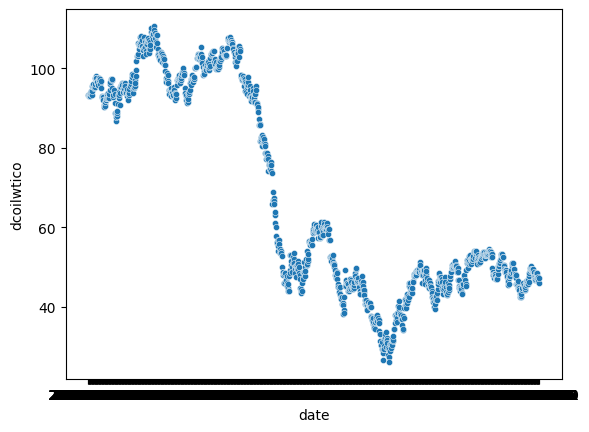

In [8]:
sns.scatterplot(x=oil_df['date'],y=oil_df['dcoilwtico'],s=20)

In [9]:
oil_df['was_oilprice_missing']=oil_df['dcoilwtico'].isna()
oil_df['dcoilwtico']=oil_df['dcoilwtico'].ffill().bfill()
oil_df.isna().sum().sum()

np.int64(0)

In [10]:
print(f"shape: {stores_df.shape}")
stores_df.head()

shape: (54, 5)


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [11]:
stores_df=stores_df.rename(columns={'type':'store_type'})
stores_df.dtypes

store_nbr      int64
city          object
state         object
store_type    object
cluster        int64
dtype: object

In [12]:
stores_df.isna().sum().sum()

np.int64(0)

In [13]:
for i,col in enumerate(stores_df.columns):
    print(f"{i+1}->    Feature:{col}            ({stores_df[col].nunique()} unique values)             {stores_df[col].unique()}")

1->    Feature:store_nbr            (54 unique values)             [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54]
2->    Feature:city            (22 unique values)             ['Quito' 'Santo Domingo' 'Cayambe' 'Latacunga' 'Riobamba' 'Ibarra'
 'Guaranda' 'Puyo' 'Ambato' 'Guayaquil' 'Salinas' 'Daule' 'Babahoyo'
 'Quevedo' 'Playas' 'Libertad' 'Cuenca' 'Loja' 'Machala' 'Esmeraldas'
 'Manta' 'El Carmen']
3->    Feature:state            (16 unique values)             ['Pichincha' 'Santo Domingo de los Tsachilas' 'Cotopaxi' 'Chimborazo'
 'Imbabura' 'Bolivar' 'Pastaza' 'Tungurahua' 'Guayas' 'Santa Elena'
 'Los Rios' 'Azuay' 'Loja' 'El Oro' 'Esmeraldas' 'Manabi']
4->    Feature:store_type            (5 unique values)             ['D' 'B' 'C' 'E' 'A']
5->    Feature:cluster            (17 unique values)             [13  8  9  4  6 15  7  3 12 16  1 10  2  5 11 14 17]


In [14]:
print(f"shape: {hol_event_df.shape}")
hol_event_df.head()

shape: (350, 6)


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


In [15]:
hol_event_df.dtypes

date           object
type           object
locale         object
locale_name    object
description    object
transferred      bool
dtype: object

In [16]:
hol_event_df.isna().sum().sum()

np.int64(0)

In [17]:
print(f"1->   Feature:date                ({hol_event_df['date'].nunique()} unique values)")
print(f"1->   Feature:description         ({hol_event_df['description'].nunique()} unique values)")
for i,col in enumerate(['type','locale','locale_name','transferred']):
    print(f"{i+2}->   Feature:{col}            ({hol_event_df[col].nunique()} unique values)             {hol_event_df[col].unique()}") 

1->   Feature:date                (312 unique values)
1->   Feature:description         (103 unique values)
2->   Feature:type            (6 unique values)             ['Holiday' 'Transfer' 'Additional' 'Bridge' 'Work Day' 'Event']
3->   Feature:locale            (3 unique values)             ['Local' 'Regional' 'National']
4->   Feature:locale_name            (24 unique values)             ['Manta' 'Cotopaxi' 'Cuenca' 'Libertad' 'Riobamba' 'Puyo' 'Guaranda'
 'Imbabura' 'Latacunga' 'Machala' 'Santo Domingo' 'El Carmen' 'Cayambe'
 'Esmeraldas' 'Ecuador' 'Ambato' 'Ibarra' 'Quevedo'
 'Santo Domingo de los Tsachilas' 'Santa Elena' 'Quito' 'Loja' 'Salinas'
 'Guayaquil']
5->   Feature:transferred            (2 unique values)             [False  True]


In [18]:
hol_event_df=hol_event_df.rename(columns={'type':'day_type'})
main_oil_df=pd.merge(main_df,oil_df,on='date',how='left')
main_oil_df.shape

(3000888, 7)

In [19]:
main_oil_df.isna().sum()

date                         0
store_nbr                    0
family                       0
sales                        0
onpromotion                  0
dcoilwtico              857142
was_oilprice_missing    857142
dtype: int64

In [20]:
missing_dates=list(set(main_df['date'].unique())-set(oil_df['date'].unique()))
print(main_df[main_df['date'].isin(missing_dates)].shape)
main_df[main_df['date'].isin(missing_dates)].head(10)


(857142, 5)


,date,store_nbr,family,sales,onpromotion
id,,,,,
7128,2013-01-05,1,AUTOMOTIVE,5.000,0
7129,2013-01-05,1,BABY CARE,0.000,0
7130,2013-01-05,1,BEAUTY,3.000,0
7131,2013-01-05,1,BEVERAGES,1160.000,0
7132,2013-01-05,1,BOOKS,0.000,0
7133,2013-01-05,1,BREAD/BAKERY,301.057,0
7134,2013-01-05,1,CELEBRATION,0.000,0
7135,2013-01-05,1,CLEANING,811.000,0
7136,2013-01-05,1,DAIRY,464.000,0


In [21]:
missing_dates_parsed = pd.to_datetime(list(missing_dates))
pd.Series(missing_dates_parsed.day_name()).value_counts()

Saturday    241
Sunday      240
Name: count, dtype: int64

In [22]:
oil_df['date'] = pd.to_datetime(oil_df['date'])

oil_df['was_oildate_missing']=False

oil_df = (oil_df.set_index('date').asfreq('D').reset_index())
oil_df['was_oildate_missing']=oil_df['was_oildate_missing'].fillna(True)
oil_df[pd.to_datetime(list(oil_df['date'])).day_name().isin(['Saturday','Sunday'])].shape

/tmp/ipykernel_44044/2312289148.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  oil_df['was_oildate_missing']=oil_df['was_oildate_missing'].fillna(True)


(486, 4)

In [23]:
oil_df['date']=oil_df['date'].astype(str)
oil_df['dcoilwtico']=oil_df['dcoilwtico'].ffill().bfill()

oil_df['was_oilprice_missing']=oil_df['was_oilprice_missing'].fillna(True)
oil_df['dcoilwtico'].isna().sum()

/tmp/ipykernel_44044/1180592478.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  oil_df['was_oilprice_missing']=oil_df['was_oilprice_missing'].fillna(True)


np.int64(0)

In [24]:
main_oil_df2=pd.merge(main_df,oil_df,on='date',how='left')
main_oil_stores_df=pd.merge(main_oil_df2,stores_df,on='store_nbr',how='left')
main_oil_stores_df.shape

(3000888, 12)

In [25]:
main_oil_stores_df.isna().sum().sum()

np.int64(0)

In [26]:
#no. of dates present in main_oil_stores_df but missing in hol_event_df
len(list(set(main_oil_stores_df['date'].unique())-set(hol_event_df['date'].unique())))

1432

In [27]:
hol_event_df[hol_event_df['transferred']] 

,date,day_type,locale,locale_name,description,transferred
19,2012-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
72,2013-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
135,2014-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
255,2016-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
266,2016-07-25,Holiday,Local,Guayaquil,Fundacion de Guayaquil,True
268,2016-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True
297,2017-01-01,Holiday,National,Ecuador,Primer dia del ano,True
303,2017-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,True
312,2017-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
324,2017-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True


In [28]:
hol_event_df[hol_event_df['day_type']=='Transfer']

,date,day_type,locale,locale_name,description,transferred
20,2012-10-12,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
73,2013-10-11,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
136,2014-10-10,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
256,2016-05-27,Transfer,National,Ecuador,Traslado Batalla de Pichincha,False
265,2016-07-24,Transfer,Local,Guayaquil,Traslado Fundacion de Guayaquil,False
269,2016-08-12,Transfer,National,Ecuador,Traslado Primer Grito de Independencia,False
298,2017-01-02,Transfer,National,Ecuador,Traslado Primer dia del ano,False
304,2017-04-13,Transfer,Local,Cuenca,Fundacion de Cuenca,False
313,2017-05-26,Transfer,National,Ecuador,Traslado Batalla de Pichincha,False
325,2017-08-11,Transfer,National,Ecuador,Traslado Primer Grito de Independencia,False


In [29]:
#converting holidays  which are transferred from  to workday
hol_event_df.loc[hol_event_df['transferred'],'day_type'] = 'HolidayTransferred'
hol_event_df.loc[hol_event_df['day_type']=='Transfer','day_type']='Holiday'
hol_event_df=hol_event_df.drop(columns=['transferred'])

#duplicates of dates in hol_event_df dataframe 
print(hol_event_df["date"].duplicated().sum())

holiday_duplicate_dates_df = hol_event_df[hol_event_df["date"].duplicated(keep=False)]
holiday_duplicate_dates_df.sort_values("date").head(10)

38


,date,day_type,locale,locale_name,description
7,2012-06-25,Holiday,Regional,Imbabura,Provincializacion de Imbabura
8,2012-06-25,Holiday,Local,Latacunga,Cantonizacion de Latacunga
9,2012-06-25,Holiday,Local,Machala,Fundacion de Machala
10,2012-07-03,Holiday,Local,Santo Domingo,Fundacion de Santo Domingo
11,2012-07-03,Holiday,Local,El Carmen,Cantonizacion de El Carmen
32,2012-12-22,Holiday,Local,Salinas,Cantonizacion de Salinas
33,2012-12-22,Additional,National,Ecuador,Navidad-3
36,2012-12-24,Additional,National,Ecuador,Navidad-1
35,2012-12-24,Bridge,National,Ecuador,Puente Navidad
39,2012-12-31,Bridge,National,Ecuador,Puente Primer dia del ano


In [30]:
store_locs = main_oil_stores_df[['store_nbr','city','state']].drop_duplicates()

nat = hol_event_df[hol_event_df['locale'] == 'National'].merge(store_locs, how='cross')
reg = hol_event_df[hol_event_df['locale'] == 'Regional'].merge(store_locs, left_on='locale_name', right_on='state')
loc = hol_event_df[hol_event_df['locale'] == 'Local'].merge(store_locs, left_on='locale_name', right_on='city')

store_holidays = (pd.concat([nat, reg, loc], ignore_index=True).drop_duplicates(subset=['date', 'store_nbr'])
                  [['date', 'store_nbr', 'day_type', 'locale', 'locale_name', 'description']])

full_df = main_oil_stores_df.merge(store_holidays, on=['date', 'store_nbr'], how='left')

In [31]:
full_df['date'].is_monotonic_increasing

True

In [32]:
g = full_df.groupby(['store_nbr','family'])['sales']
full_df['16day_lag']=g.shift(16)
full_df['28day_lag']=g.shift(28)
full_df['16day_roll'] = g.transform(lambda s: s.shift(16).rolling(16, min_periods=12).mean())

In [33]:
print(full_df.shape)
full_df.head()

(3000888, 19)


,date,store_nbr,family,sales,onpromotion,dcoilwtico,was_oilprice_missing,was_oildate_missing,city,state,store_type,cluster,day_type,locale,locale_name,description,16day_lag,28day_lag,16day_roll
0,2013-01-01,1,AUTOMOTIVE,0.0,0,93.14,True,False,Quito,Pichincha,D,13,Holiday,National,Ecuador,Primer dia del ano,NaN,NaN,NaN
1,2013-01-01,1,BABY CARE,0.0,0,93.14,True,False,Quito,Pichincha,D,13,Holiday,National,Ecuador,Primer dia del ano,NaN,NaN,NaN
2,2013-01-01,1,BEAUTY,0.0,0,93.14,True,False,Quito,Pichincha,D,13,Holiday,National,Ecuador,Primer dia del ano,NaN,NaN,NaN
3,2013-01-01,1,BEVERAGES,0.0,0,93.14,True,False,Quito,Pichincha,D,13,Holiday,National,Ecuador,Primer dia del ano,NaN,NaN,NaN
4,2013-01-01,1,BOOKS,0.0,0,93.14,True,False,Quito,Pichincha,D,13,Holiday,National,Ecuador,Primer dia del ano,NaN,NaN,NaN


In [34]:
full_df.isna().sum()

date                          0
store_nbr                     0
family                        0
sales                         0
onpromotion                   0
dcoilwtico                    0
was_oilprice_missing          0
was_oildate_missing           0
city                          0
state                         0
store_type                    0
cluster                       0
day_type                2733291
locale                  2733291
locale_name             2733291
description             2733291
16day_lag                 28512
28day_lag                 49896
16day_roll                48114
dtype: int64

In [35]:
full_df['day_type']=full_df['day_type'].fillna('no_day_type')
full_df['locale']=full_df['locale'].fillna('no_locale')
full_df['locale_name']=full_df['locale_name'].fillna('no_locale_name')
full_df['description']=full_df['description'].fillna('no_description')

In [36]:
full_df['date']=pd.to_datetime(full_df['date'])
full_df['year']=full_df['date'].dt.year
full_df['monthofyear']=full_df['date'].dt.month
full_df['dayofmonth']=full_df['date'].dt.day
full_df['dayofweek']=full_df['date'].dt.dayofweek
full_df['is_weekend']=full_df['dayofweek'].isin([5,6])

month_to_season={12:0,1:0,2:0,3:1,4:1,5:1,6:2,7:2,8:2,9:3,10:3,11:3}
full_df['season']=full_df['monthofyear'].map(month_to_season)
full_df.isna().sum()

date                        0
store_nbr                   0
family                      0
sales                       0
onpromotion                 0
dcoilwtico                  0
was_oilprice_missing        0
was_oildate_missing         0
city                        0
state                       0
store_type                  0
cluster                     0
day_type                    0
locale                      0
locale_name                 0
description                 0
16day_lag               28512
28day_lag               49896
16day_roll              48114
year                        0
monthofyear                 0
dayofmonth                  0
dayofweek                   0
is_weekend                  0
season                      0
dtype: int64


# Seasons
* 0 : Winter
* 1 : Spring
* 2 : Summer
* 3 : Autumn 

In [37]:
full_df.dtypes

date                    datetime64[ns]
store_nbr                        int64
family                          object
sales                          float64
onpromotion                      int64
dcoilwtico                     float64
was_oilprice_missing              bool
was_oildate_missing               bool
city                            object
state                           object
store_type                      object
cluster                          int64
day_type                        object
locale                          object
locale_name                     object
description                     object
16day_lag                      float64
28day_lag                      float64
16day_roll                     float64
year                             int32
monthofyear                      int32
dayofmonth                       int32
dayofweek                        int32
is_weekend                        bool
season                           int64
dtype: object

In [38]:
full_df['store_nbr']=full_df['store_nbr'].astype('object')
full_df['cluster']=full_df['cluster'].astype('object')

In [39]:
y=full_df['sales']
x=full_df.drop(columns=['sales'])

unique_dates=x['date'].unique()
test_dates=unique_dates[-16:]
test_mask=x['date'].isin(test_dates)

x_train,y_train=x[~test_mask].copy(), y[~test_mask].copy()
x_test,y_test=x[test_mask].copy(), y[test_mask].copy()

x_test['date'].nunique()

16

In [40]:
x_test.shape

(28512, 24)

In [41]:
del main_df,oil_df,stores_df,hol_event_df
del missing_dates_parsed,missing_dates,holiday_duplicate_dates_df
del main_oil_df,main_oil_df2,main_oil_stores_df
del full_df,x,y,test_mask

In [42]:
x_train.head()

,date,store_nbr,family,onpromotion,dcoilwtico,was_oilprice_missing,was_oildate_missing,city,state,store_type,...,description,16day_lag,28day_lag,16day_roll,year,monthofyear,dayofmonth,dayofweek,is_weekend,season
0,2013-01-01,1,AUTOMOTIVE,0,93.14,True,False,Quito,Pichincha,D,...,Primer dia del ano,NaN,NaN,NaN,2013,1,1,1,False,0
1,2013-01-01,1,BABY CARE,0,93.14,True,False,Quito,Pichincha,D,...,Primer dia del ano,NaN,NaN,NaN,2013,1,1,1,False,0
2,2013-01-01,1,BEAUTY,0,93.14,True,False,Quito,Pichincha,D,...,Primer dia del ano,NaN,NaN,NaN,2013,1,1,1,False,0
3,2013-01-01,1,BEVERAGES,0,93.14,True,False,Quito,Pichincha,D,...,Primer dia del ano,NaN,NaN,NaN,2013,1,1,1,False,0
4,2013-01-01,1,BOOKS,0,93.14,True,False,Quito,Pichincha,D,...,Primer dia del ano,NaN,NaN,NaN,2013,1,1,1,False,0


In [43]:
x_train.dtypes

date                    datetime64[ns]
store_nbr                       object
family                          object
onpromotion                      int64
dcoilwtico                     float64
was_oilprice_missing              bool
was_oildate_missing               bool
city                            object
state                           object
store_type                      object
cluster                         object
day_type                        object
locale                          object
locale_name                     object
description                     object
16day_lag                      float64
28day_lag                      float64
16day_roll                     float64
year                             int32
monthofyear                      int32
dayofmonth                       int32
dayofweek                        int32
is_weekend                        bool
season                           int64
dtype: object

In [44]:
x_train.shape

(2972376, 24)

<Axes: xlabel='sales'>

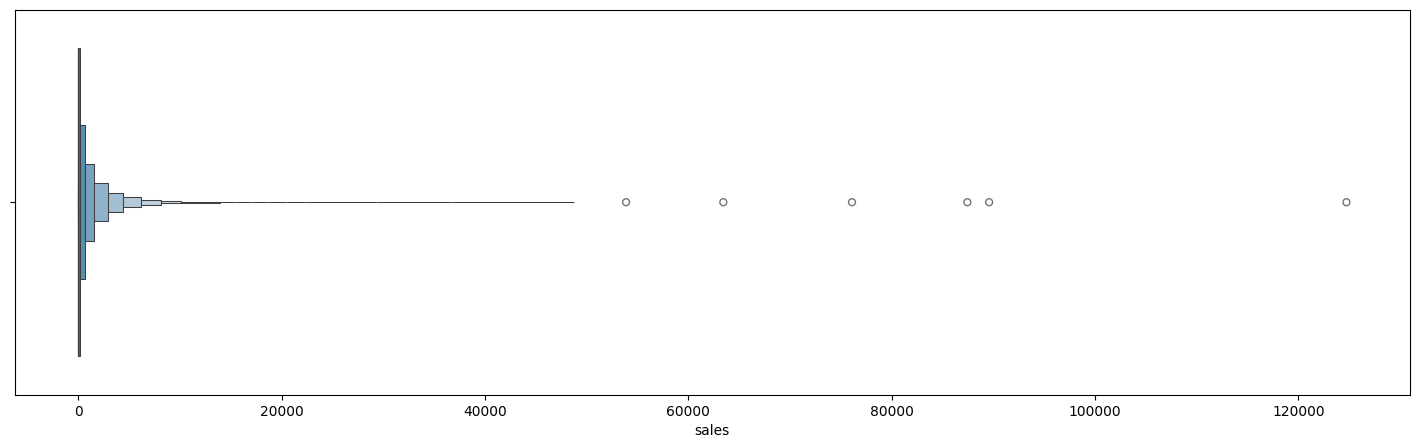

In [45]:
plt.figure(figsize=(18,5))
sns.boxenplot(x=y_train,orient='h')

<Axes: xlabel='sales', ylabel='family'>

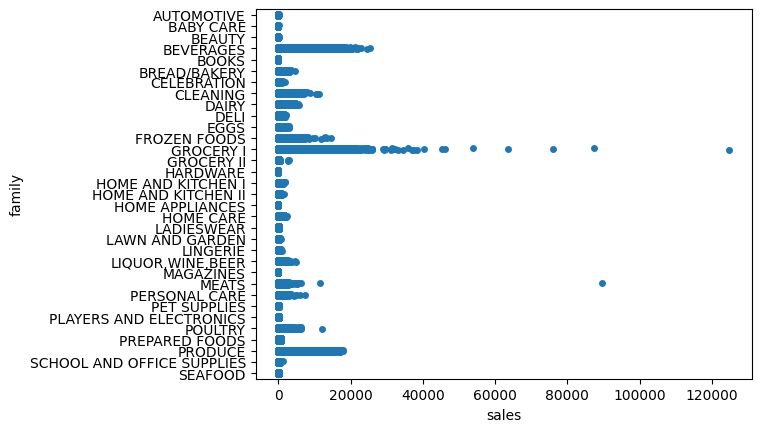

In [46]:
sns.stripplot(y=x_train['family'],x=y_train)

Text(0.5, 1.0, 'Sales from train set with log1p transform')

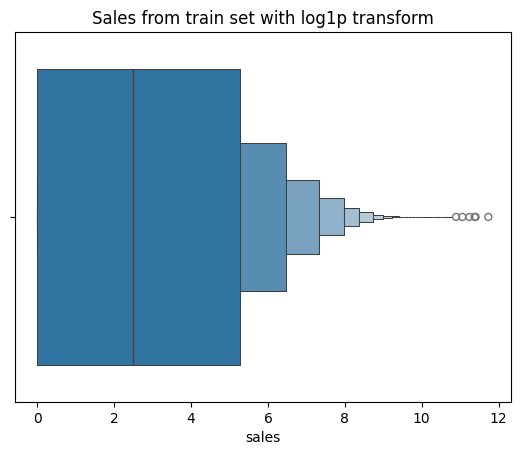

In [47]:
y_train_log=np.log1p(y_train)
y_test_log=np.log1p(y_test)
y_train_log_plot=sns.boxenplot(x=y_train_log,orient='h')
y_train_log_plot.set_title('Sales from train set with log1p transform')

In [48]:
x_train.loc[y_train[y_train>50000].index]

,date,store_nbr,family,onpromotion,dcoilwtico,was_oilprice_missing,was_oildate_missing,city,state,store_type,...,description,16day_lag,28day_lag,16day_roll,year,monthofyear,dayofmonth,dayofweek,is_weekend,season
2139699,2016-04-18,45,GROCERY I,38,39.74,False,False,Quito,Pichincha,A,...,Terremoto Manabi+2,17246.000,8825.000,9847.500000,2016,4,18,0,False,1
2144154,2016-04-21,20,GROCERY I,53,43.18,False,False,Quito,Pichincha,B,...,Terremoto Manabi+5,4634.068,3502.602,5064.412625,2016,4,21,3,False,1
2145045,2016-04-21,45,GROCERY I,44,43.18,False,False,Quito,Pichincha,A,...,Terremoto Manabi+5,8793.000,7053.000,10210.625000,2016,4,21,3,False,1
2153031,2016-04-26,2,GROCERY I,30,42.52,False,False,Quito,Pichincha,D,...,Terremoto Manabi+10,5474.000,3304.000,4430.500000,2016,4,26,1,False,1
2163723,2016-05-02,2,GROCERY I,59,44.75,False,False,Quito,Pichincha,D,...,Terremoto Manabi+16,5019.000,4214.000,4437.250000,2016,5,2,0,False,1
2445984,2016-10-07,39,MEATS,0,49.76,False,False,Cuenca,Azuay,B,...,no_description,138.903,111.196,154.955000,2016,10,7,4,False,3


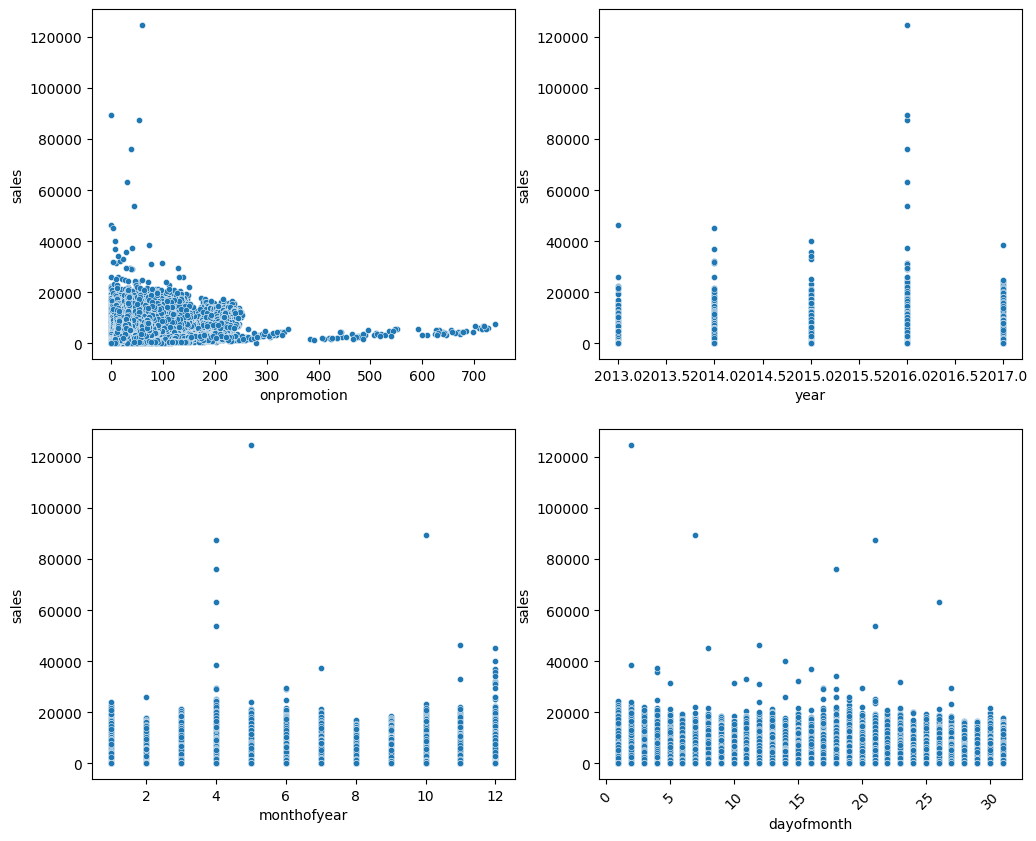

In [50]:
features=['onpromotion','year','monthofyear','dayofmonth']
fig,axes=plt.subplots(2,2,figsize=(12,10))
axes=axes.flatten()
for i,feature in enumerate(features):
    sns.scatterplot(x=x_train[feature],y=y_train,ax=axes[i],s=20)
    plt.xticks(rotation=45)
    
del features,fig,axes

outliers at about 4-5month are present ,maybe due to 2016's march's ecuador's earthquake , but  for 10th month we need to investigate

In [51]:
x_train['earthquake_aftermath']=x_train['date'].between('2016-04-16','2016-05-05')
x_test['earthquake_aftermath']=False

In [52]:
mask=(x_train['date'] == '2016-10-07') & (x_train['family'] == 'MEATS')
x_train.loc[mask].loc[y_train.loc[mask].sort_values(ascending=False).index].head()

,date,store_nbr,family,onpromotion,dcoilwtico,was_oilprice_missing,was_oildate_missing,city,state,store_type,...,16day_lag,28day_lag,16day_roll,year,monthofyear,dayofmonth,dayofweek,is_weekend,season,earthquake_aftermath
2445984,2016-10-07,39,MEATS,0,49.76,False,False,Cuenca,Azuay,B,...,138.903,111.196,154.955000,2016,10,7,4,False,3,False
2446215,2016-10-07,45,MEATS,53,49.76,False,False,Quito,Pichincha,A,...,848.605,1908.916,1241.121813,2016,10,7,4,False,3,False
2446248,2016-10-07,46,MEATS,49,49.76,False,False,Quito,Pichincha,A,...,794.303,1819.058,1057.219877,2016,10,7,4,False,3,False
2446281,2016-10-07,47,MEATS,53,49.76,False,False,Quito,Pichincha,A,...,778.079,1710.177,926.908937,2016,10,7,4,False,3,False
2446182,2016-10-07,44,MEATS,54,49.76,False,False,Quito,Pichincha,A,...,662.729,1372.787,889.639189,2016,10,7,4,False,3,False


In [53]:
mask2=mask & (x_train['city']=='Cuenca')
x_train[mask2]

,date,store_nbr,family,onpromotion,dcoilwtico,was_oilprice_missing,was_oildate_missing,city,state,store_type,...,16day_lag,28day_lag,16day_roll,year,monthofyear,dayofmonth,dayofweek,is_weekend,season,earthquake_aftermath
2445918,2016-10-07,37,MEATS,37,49.76,False,False,Cuenca,Azuay,D,...,198.024,399.866,224.125562,2016,10,7,4,False,3,False
2445984,2016-10-07,39,MEATS,0,49.76,False,False,Cuenca,Azuay,B,...,138.903,111.196,154.955000,2016,10,7,4,False,3,False
2446116,2016-10-07,42,MEATS,38,49.76,False,False,Cuenca,Azuay,D,...,192.208,291.315,206.737376,2016,10,7,4,False,3,False


In [54]:
print(f'sales in cuenca at 2016-10-7 for meat: {list(y_train[mask2].values)}\n\n')

mask3=(x_train['store_nbr']==39)&(x_train['family']=='MEATS')&(y_train>6000)
x_train[mask3]

sales in cuenca at 2016-10-7 for meat: [np.float64(359.421), np.float64(89576.36), np.float64(280.642)]




,date,store_nbr,family,onpromotion,dcoilwtico,was_oilprice_missing,was_oildate_missing,city,state,store_type,...,16day_lag,28day_lag,16day_roll,year,monthofyear,dayofmonth,dayofweek,is_weekend,season,earthquake_aftermath
2445984,2016-10-07,39,MEATS,0,49.76,False,False,Cuenca,Azuay,B,...,138.903,111.196,154.955,2016,10,7,4,False,3,False


We can see that the sales about 90k  look unusual and impossible on that date as there was no special day 

In [55]:
s39_sales_mask=(x_train['family']=='MEATS')&(x_train['date'].between('2016-09-25','2016-10-10'))&(x_train['store_nbr']==39)
x_train.loc[y_train[s39_sales_mask].sort_values(ascending=False).index]

,date,store_nbr,family,onpromotion,dcoilwtico,was_oilprice_missing,was_oildate_missing,city,state,store_type,...,16day_lag,28day_lag,16day_roll,year,monthofyear,dayofmonth,dayofweek,is_weekend,season,earthquake_aftermath
2445984,2016-10-07,39,MEATS,0,49.76,False,False,Cuenca,Azuay,B,...,138.90300,111.19600,154.955000,2016,10,7,4,False,3,False
2433510,2016-09-30,39,MEATS,0,47.72,False,False,Cuenca,Azuay,B,...,131.27600,140.24900,153.090437,2016,9,30,4,False,3,False
2431728,2016-09-29,39,MEATS,22,47.72,False,False,Cuenca,Azuay,B,...,168.09799,197.82900,153.500812,2016,9,29,3,False,3,False
2437074,2016-10-02,39,MEATS,0,47.72,True,True,Cuenca,Azuay,B,...,170.95600,182.69699,161.478875,2016,10,2,6,True,3,False
2444202,2016-10-06,39,MEATS,22,50.44,False,False,Cuenca,Azuay,B,...,179.88500,216.88800,153.750937,2016,10,6,3,False,3,False
2447766,2016-10-08,39,MEATS,0,49.76,True,True,Cuenca,Azuay,B,...,217.45500,173.33400,159.960937,2016,10,8,5,True,3,False
2435292,2016-10-01,39,MEATS,0,47.72,True,True,Cuenca,Azuay,B,...,234.50700,195.94101,158.216312,2016,10,1,5,True,3,False
2449548,2016-10-09,39,MEATS,0,49.76,True,True,Cuenca,Azuay,B,...,2224.35500,145.80700,291.633375,2016,10,9,6,True,3,False
2440638,2016-10-04,39,MEATS,0,48.67,False,False,Cuenca,Azuay,B,...,124.28400,137.36000,159.054875,2016,10,4,1,False,3,False
2424600,2016-09-25,39,MEATS,0,44.36,True,True,Cuenca,Azuay,B,...,111.19600,168.21300,458.524687,2016,9,25,6,True,3,False


It looks like promotion on a day is effecting next day sale mostly

In [56]:
prev_promo = x_train.groupby(['store_nbr', 'family'])['onpromotion'].shift(1)

y_train.loc[
    (x_train['family'] == 'MEATS')
    & (x_train['store_nbr'] == 39)
    & (x_train['date'].between('2016-01-01', '2016-10-15'))
    & (prev_promo > 20)
]

1947024        0.00000
1959498      153.38800
2046816      105.55100
2196504      142.25299
2258874     5133.53900
2271348     5156.13300
2333718     5177.57100
2346192      126.77600
2371140     4988.73500
2383614      140.24900
2396088      111.19600
2421036     2224.35500
2433510     2351.34400
2445984    89576.36000
2458458      155.92600
Name: sales, dtype: float64

In [57]:
#now this seems to be more right
idx=2445984
rows_per_date=1782
y_train.loc[idx]=8957.636

y_train_log=np.log1p(y_train)
x_train.loc[idx+16*rows_per_date,'16day_lag']=8957.636
x_train.loc[idx+28*rows_per_date,'28day_lag']=8957.636

for i in range(16, 32):
    x_train.loc[ idx+ i*rows_per_date, '16day_roll'] = y_train.loc[idx +(i-31)*rows_per_date : idx+(i-16)*rows_per_date:rows_per_date].mean()

In [58]:
x_train.drop(columns=['date','description'],inplace=True)
x_test.drop(columns=['date','description'],inplace=True)

In [59]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import BaseEstimator,TransformerMixin
from feature_engine.creation import CyclicalFeatures
from sklearn.compose import ColumnTransformer

normal_time_series_features=['monthofyear','dayofweek','season']
cat_features=['store_nbr','family','city','state','cluster','store_type','day_type','locale','locale_name']

class mycfe(BaseEstimator,TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        x=X.copy()
        month = x['monthofyear'].to_numpy()
        day = x['dayofmonth'].to_numpy()
        year=x['year'].to_numpy()

        days_in_month = np.select( 
            [
                np.isin(month, [1, 3, 5, 7, 8, 10, 12]),
                np.isin(month, [4, 6, 9, 11]),
                (month ==2 ) & (((year % 4 ==0) & (year % 100!= 0)) | (year % 400==0)),
                (month == 2)
            ],
            [31, 30, 29,28],
            default=np.nan
        )

        angle = 2 * np.pi * (day - 1) / days_in_month
        x['day_sin']=np.sin(angle)
        x['day_cos']=np.cos(angle)
        x.drop(columns=['monthofyear'],inplace=True)
        return x
    
    def get_feature_names_out(self, input_features=None):
        return np.array(['dayofmonth','year','day_sin','day_cos'], dtype=object)

preprocessor=ColumnTransformer(transformers=[
    ('onehot_encoder',OneHotEncoder(sparse_output=True,handle_unknown='ignore'),cat_features),
    ('cyclic_encoder1',CyclicalFeatures(max_values={'dayofweek':7,'monthofyear':12,'season':4}),normal_time_series_features),
    ('cyclic_encoder2',mycfe(),['dayofmonth','monthofyear','year']),               #encodes dayofmonth only
],remainder='passthrough')
x_train_processed=preprocessor.fit_transform(x_train)
x_test_processed=preprocessor.transform(x_test)

In [60]:
# del x_train,x_test
encoded_features=preprocessor.get_feature_names_out()
x_train_processed.shape

(2972376, 204)

In [61]:
from sklearn.model_selection import TimeSeriesSplit
import optuna 
from sklearn.model_selection import cross_val_score
from xgboost import XGBRegressor

tscv=TimeSeriesSplit(n_splits=3,test_size=1782*16)
sampler=optuna.samplers.TPESampler(seed=42)

def objective(trial):
    params={
        'max_depth':trial.suggest_int('max_depth',3,9),
        'learning_rate':trial.suggest_float('learning_rate',0.02,0.3,log=True),
        'n_estimators':trial.suggest_int('n_estimators',200,1000),
        'subsample':trial.suggest_float('subsample',0.4,0.9),
        'min_child_weight':trial.suggest_int('min_child_weight',1,20),
        'reg_lambda':trial.suggest_int('reg_lambda',1,30,log=True),
        'gamma':trial.suggest_int('gamma',0,10)
    }

    test_model=XGBRegressor(**params,random_state=42,objective='reg:squarederror',tree_method='hist',verbosity=0,device='cuda')
    scores= cross_val_score(test_model,x_train_processed,y_train_log,cv=tscv,scoring='neg_root_mean_squared_error')
    return -scores.mean()

study =optuna.create_study(direction='minimize',sampler=sampler)
study.optimize(objective,n_trials=25)

/home/umesh/ML/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-11-22 23:55:08,140] A new study created in memory with name: no-name-d20affd7-983a-4e5b-aeeb-7f8f3904eb14
[I 2026-11-22 23:55:42,521] Trial 0 finished with value: 0.40857361667040015 and parameters: {'max_depth': 5, 'learning_rate': 0.262516606324193, 'n_estimators': 786, 'subsample': 0.6993292420985183, 'min_child_weight': 4, 'reg_lambda': 1, 'gamma': 0}. Best is trial 0 with value: 0.40857361667040015.
[I 2026-11-22 23:56:21,076] Trial 1 finished with value: 0.397789454012001 and parameters: {'max_depth': 9, 'learning_rate': 0.10185822566867639, 'n_estimators': 767, 'subsample': 0.41029224714790125, 'min_child_weight': 20, 'reg_lambda': 15, 'gamma': 2}. Best is trial 1 with value: 0.397789454012001.
[I 2026-11-22 23:56:41,742

In [62]:
study.best_params

{'max_depth': 9,
 'learning_rate': 0.09520661148160972,
 'n_estimators': 643,
 'subsample': 0.5658482414834256,
 'min_child_weight': 17,
 'reg_lambda': 9,
 'gamma': 0}

In [63]:
from xgboost import XGBRegressor
final_model=XGBRegressor(random_state=42,objective='reg:squarederror',tree_method='hist',verbosity=0,device='cuda',
 max_depth=9,
 learning_rate=0.09520661148160972,
 n_estimators=643,
 subsample=0.5658482414834256,
 min_child_weight=17,
 reg_lambda=9,
 gamma=0)
final_model.fit(x_train_processed,y_train_log)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,'cuda'
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [64]:
from sklearn.metrics import r2_score,root_mean_squared_log_error
y_predict_final=np.expm1(final_model.predict(x_test_processed))
print('r2_score:',r2_score(y_test,y_predict_final))
print('root_mean_squared_log_error:',root_mean_squared_log_error(y_test,y_predict_final))
y_train_predict_final=np.expm1(final_model.predict(x_train_processed))
print('\n\nr2_score for training set:',r2_score(y_train,y_train_predict_final))

r2_score: 0.9597357229370592
root_mean_squared_log_error: 0.41784065290410594


r2_score for training set: 0.9501768915291234


In [65]:
pred_log = final_model.predict(x_test_processed)
res = pd.DataFrame({
    'date': np.repeat(unique_dates[-16:], 1782),
    'family': x_test['family'].values,
    'se': (pred_log - y_test_log.values) ** 2,
})
print('overall RMSLE:', res['se'].mean() ** 0.5)
print(res.groupby('date')['se'].mean().pow(0.5))

overall RMSLE: 0.4178406527087536
date
2017-07-31    0.401901
2017-08-01    0.391295
2017-08-02    0.399553
2017-08-03    0.395709
2017-08-04    0.408780
2017-08-05    0.384254
2017-08-06    0.404333
2017-08-07    0.407905
2017-08-08    0.407880
2017-08-09    0.394383
2017-08-10    0.403960
2017-08-11    0.424436
2017-08-12    0.446121
2017-08-13    0.441858
2017-08-14    0.451004
2017-08-15    0.505040
Name: se, dtype: float64


Text(0.5, 1.0, 'Actual vs Predicted Sales')

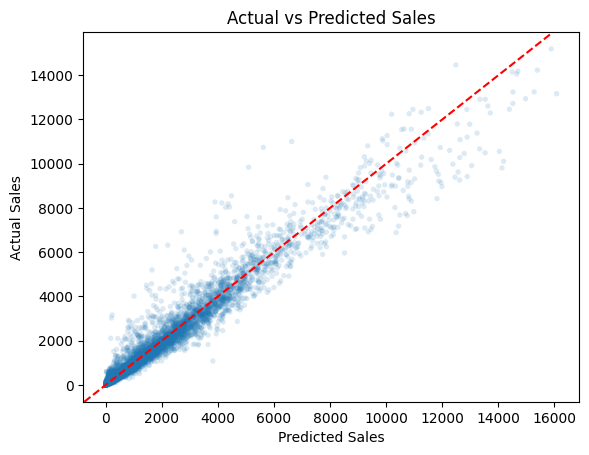

In [66]:
evaluation_plot=sns.scatterplot(x=y_predict_final,y=y_test,s=15,alpha=0.15,edgecolor='none')
plt.axline((0,0),slope=1,linestyle='--',color='red')
evaluation_plot.set_xlabel('Predicted Sales')
evaluation_plot.set_ylabel('Actual Sales')
evaluation_plot.set_title('Actual vs Predicted Sales')

Text(0.5, 0, 'log error')

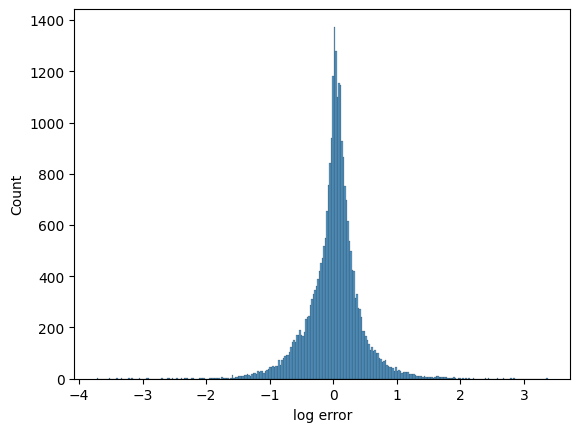

In [67]:
error=final_model.predict(x_test_processed)-y_test_log
error_dist=sns.histplot(data=error)
error_dist.set_xlabel('log error')

In [68]:
import shap
explainer=shap.TreeExplainer(final_model)
x_test_dense=x_test_processed.toarray()
x_test_for_shap=pd.DataFrame(x_test_dense,columns=encoded_features)
shap_values=explainer(x_test_for_shap)

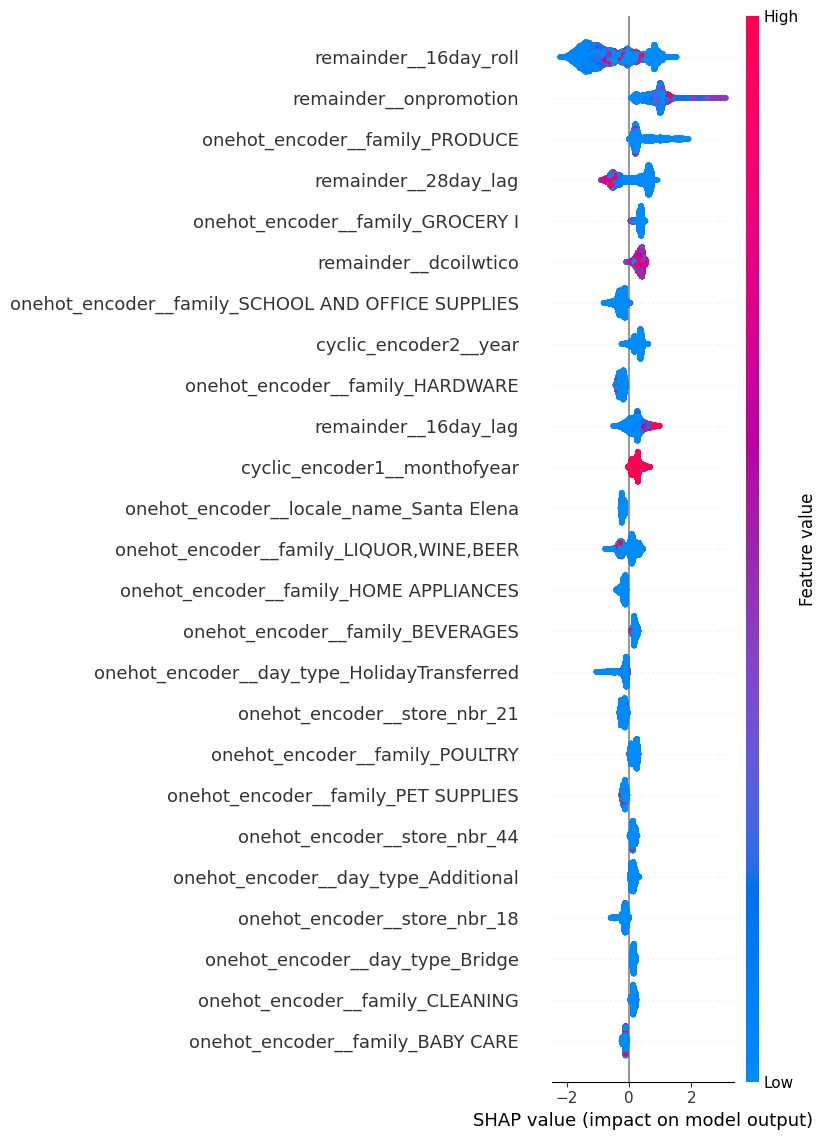

In [69]:
del x_train_processed,x_test_processed
shap.summary_plot(shap_values,x_test_for_shap,max_display=25)